In [1]:
# Week 4 — Day 1: Statistics
# Descriptive Statistics for Business Reporting

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sys

print("Python version:", sys.version)
print("Statistics analysis started successfully!")

Python version: 3.12.4 (tags/v3.12.4:8e8a4ba, Jun  6 2024, 19:30:16) [MSC v.1940 64 bit (AMD64)]
Statistics analysis started successfully!


In [2]:
# Sample sales data for two business regions

data = {
    "Region": [
        "North", "North", "North", "North", "North",
        "North", "North", "North", "North", "North",
        "South", "South", "South", "South", "South",
        "South", "South", "South", "South", "South"
    ],
    "Sales": [
        12000, 15000, 18000, 15000, 22000,
        25000, 18000, 30000, 15000, 20000,
        10000, 14000, 16000, 18000, 20000,
        22000, 24000, 18000, 26000, 28000
    ]
}

df = pd.DataFrame(data)

print("Business Sales Dataset:")
display(df.head(10))

print("\nDataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())

Business Sales Dataset:


,Region,Sales
0,North,12000
1,North,15000
2,North,18000
3,North,15000
4,North,22000
5,North,25000
6,North,18000
7,North,30000
8,North,15000
9,North,20000



Dataset shape: (20, 2)

Missing values:
Region    0
Sales     0
dtype: int64


In [3]:
sales = df["Sales"]

statistics_summary = pd.DataFrame({
    "Measure": [
        "Mean",
        "Median",
        "Mode",
        "Variance",
        "Standard Deviation",
        "Minimum",
        "Maximum"
    ],
    "Value": [
        sales.mean(),
        sales.median(),
        sales.mode().tolist(),
        sales.var(),
        sales.std(),
        sales.min(),
        sales.max()
    ]
})

print("Descriptive Statistics:")
display(statistics_summary)

Descriptive Statistics:


,Measure,Value
0,Mean,19300.0
1,Median,18000.0
2,Mode,[18000]
3,Variance,28747368.421053
4,Standard Deviation,5361.657246
5,Minimum,10000
6,Maximum,30000


In [4]:
regional_stats = df.groupby("Region")["Sales"].agg(
    ["count", "mean", "median", "std", "var", "min", "max"]
)

regional_stats.columns = [
    "Count",
    "Mean",
    "Median",
    "Standard Deviation",
    "Variance",
    "Minimum",
    "Maximum"
]

print("Regional Sales Statistics:")
display(regional_stats.round(2))

Regional Sales Statistics:


,Count,Mean,Median,Standard Deviation,Variance,Minimum,Maximum
Region,,,,,,,
North,10,19000.0,18000.0,5436.50,29555555.56,12000,30000
South,10,19600.0,19000.0,5561.77,30933333.33,10000,28000


Frequency Distribution:


,Frequency
Sales_Range,
"(9980.0, 14000.0]",3
"(14000.0, 18000.0]",8
"(18000.0, 22000.0]",4
"(22000.0, 26000.0]",3
"(26000.0, 30000.0]",2


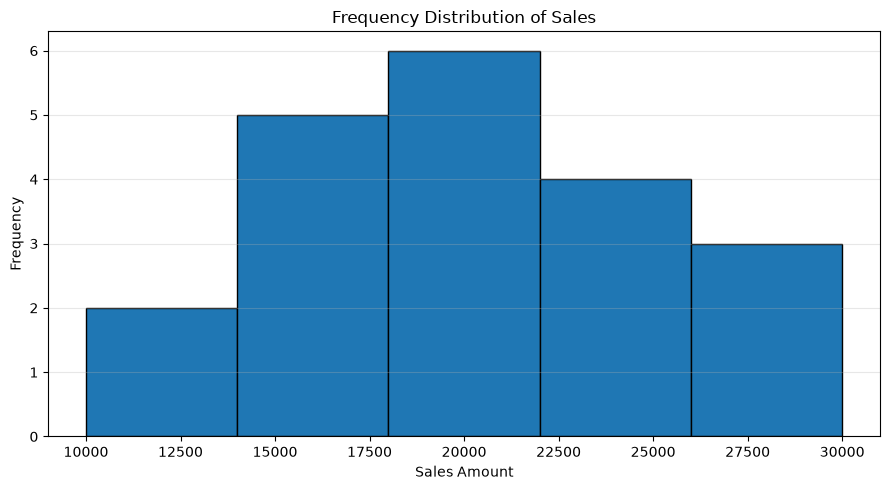

Skewness: 0.337
Interpretation: The distribution is approximately symmetric.


In [5]:
# Create sales intervals
df["Sales_Range"] = pd.cut(
    df["Sales"],
    bins=5
)

frequency = df["Sales_Range"].value_counts().sort_index()

print("Frequency Distribution:")
display(frequency.rename("Frequency").to_frame())

# Plot the frequency distribution
plt.figure(figsize=(9, 5))
plt.hist(df["Sales"], bins=5, edgecolor="black")
plt.title("Frequency Distribution of Sales")
plt.xlabel("Sales Amount")
plt.ylabel("Frequency")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Interpret skewness
skewness = sales.skew()

print("Skewness:", round(skewness, 3))

if skewness > 0.5:
    print("Interpretation: The distribution is positively skewed.")
elif skewness < -0.5:
    print("Interpretation: The distribution is negatively skewed.")
else:
    print("Interpretation: The distribution is approximately symmetric.")

In [6]:
# Calculate quartiles
q1 = sales.quantile(0.25)
q2 = sales.quantile(0.50)
q3 = sales.quantile(0.75)

print("First Quartile (Q1):", q1)
print("Second Quartile (Q2 / Median):", q2)
print("Third Quartile (Q3):", q3)
print("Interquartile Range (IQR):", q3 - q1)

# Calculate selected percentiles
percentiles = sales.quantile([0.10, 0.25, 0.50, 0.75, 0.90])

print("\nSelected Percentiles:")
display(percentiles.rename("Sales Value").to_frame())

First Quartile (Q1): 15000.0
Second Quartile (Q2 / Median): 18000.0
Third Quartile (Q3): 22500.0
Interquartile Range (IQR): 7500.0

Selected Percentiles:


,Sales Value
0.10,13800.0
0.25,15000.0
0.50,18000.0
0.75,22500.0
0.90,26200.0


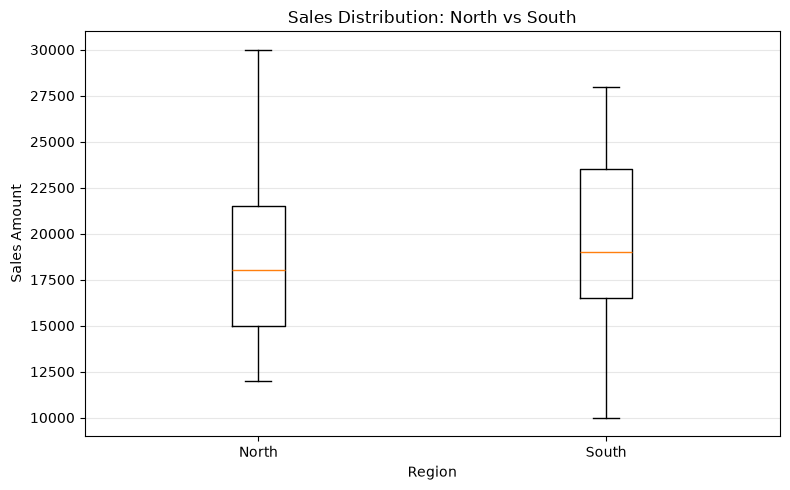

North median sales: 18000.0
South median sales: 19000.0
North mean sales: 19000.0
South mean sales: 19600.0


In [7]:
north_sales = df.loc[df["Region"] == "North", "Sales"]
south_sales = df.loc[df["Region"] == "South", "Sales"]

plt.figure(figsize=(8, 5))

plt.boxplot(
    [north_sales, south_sales],
    tick_labels=["North", "South"]
)

plt.title("Sales Distribution: North vs South")
plt.xlabel("Region")
plt.ylabel("Sales Amount")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("North median sales:", north_sales.median())
print("South median sales:", south_sales.median())
print("North mean sales:", round(north_sales.mean(), 2))
print("South mean sales:", round(south_sales.mean(), 2))

In [8]:
north_mean = north_sales.mean()
south_mean = south_sales.mean()

print("BUSINESS INSIGHTS")
print("-" * 40)

if north_mean > south_mean:
    print("North has a higher average sales value than South.")
elif south_mean > north_mean:
    print("South has a higher average sales value than North.")
else:
    print("Both regions have the same average sales value.")

print(
    f"Overall average sales: ₹{sales.mean():,.2f}"
)

print(
    f"Overall median sales: ₹{sales.median():,.2f}"
)

print(
    f"Sales standard deviation: ₹{sales.std():,.2f}"
)

print(
    "The standard deviation describes how spread out "
    "the sales values are around their mean."
)

print(
    "Quartiles and percentiles help identify the distribution "
    "of sales and compare performance across regions."
)

BUSINESS INSIGHTS
----------------------------------------
South has a higher average sales value than North.
Overall average sales: ₹19,300.00
Overall median sales: ₹18,000.00
Sales standard deviation: ₹5,361.66
The standard deviation describes how spread out the sales values are around their mean.
Quartiles and percentiles help identify the distribution of sales and compare performance across regions.


In [9]:
print("CONCLUSION")
print("-" * 40)

print(
    "Descriptive statistics were used to summarize business sales "
    "data using measures of central tendency and dispersion."
)

print(
    "A frequency distribution was plotted to understand the shape "
    "of the sales distribution."
)

print(
    "Quartiles and percentiles were calculated to understand "
    "the spread of sales values."
)

print(
    "Side-by-side box plots were used to compare sales distributions "
    "between North and South."
)

print(
    "These statistical measures support data-driven business "
    "reporting and regional performance analysis."
)

CONCLUSION
----------------------------------------
Descriptive statistics were used to summarize business sales data using measures of central tendency and dispersion.
A frequency distribution was plotted to understand the shape of the sales distribution.
Quartiles and percentiles were calculated to understand the spread of sales values.
Side-by-side box plots were used to compare sales distributions between North and South.
These statistical measures support data-driven business reporting and regional performance analysis.
